# 03 — Baselines, first models and Kaggle submission
**Owner: Eno Daniel Simeon (Modelling & Submission)**

All models are scored with ROC AUC on the same 5 stratified folds from notebook 02.

In [1]:
import sys, time
sys.path.append("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from src.preprocess import (load_data, clean, feature_columns, linear_preprocessor,
                            tree_frame, get_folds, TARGET, ID_COL)

train, test = load_data()
train_c, test_c = clean(train), clean(test)
y = train_c[TARGET].values
FOLDS = get_folds(y)   # same 5 stratified folds as notebook 02

results = []

def report(name, oof, fold_scores, seconds):
    results.append({"model": name, "OOF AUC": roc_auc_score(y, oof),
                    "fold mean": np.mean(fold_scores), "fold std": np.std(fold_scores),
                    "time, s": round(seconds, 1)})
    print(f"{name:32s} OOF AUC = {results[-1]['OOF AUC']:.5f} ± {np.std(fold_scores):.5f}")

## 1. Trivial baselines
* **Constant**: predict the training share of satisfied passengers for everyone (AUC = 0.5 by definition).
* **Simple rule**: use one feature as the score — the `Online boarding` rating, the
  strongest single feature from the EDA. No training at all.

In [2]:
oof = np.zeros(len(y)); scores = []
for tr, va in FOLDS:
    oof[va] = y[tr].mean(); scores.append(roc_auc_score(y[va], oof[va]))
report("Constant (class prior)", oof, scores, 0)

score = train_c["Online boarding"].values.astype(float)
report("Rule: Online boarding rating", score,
       [roc_auc_score(y[va], score[va]) for _, va in FOLDS], 0)

rule = (train_c["Class"].eq("Business").astype(int) * 10 + train_c["Online boarding"]).values
report("Rule: Business class + boarding", rule,
       [roc_auc_score(y[va], rule[va]) for _, va in FOLDS], 0)

Constant (class prior)           OOF AUC = 0.50000 ± 0.00000
Rule: Online boarding rating     OOF AUC = 0.84039 ± 0.00112


Rule: Business class + boarding  OOF AUC = 0.88019 ± 0.00112


## 2. Logistic regression (linear model)
Preprocessing (log, scaling, one-hot) is inside the pipeline → refit on each training fold.

In [3]:
X_lin, X_lin_test = train_c[feature_columns()], test_c[feature_columns()]
oof = np.zeros(len(y)); scores = []; t = time.time()
for tr, va in FOLDS:
    model = make_pipeline(linear_preprocessor(), LogisticRegression(max_iter=1000, C=1.0))
    model.fit(X_lin.iloc[tr], y[tr])
    oof[va] = model.predict_proba(X_lin.iloc[va])[:, 1]
    scores.append(roc_auc_score(y[va], oof[va]))
report("Logistic regression", oof, scores, time.time() - t)
oof_lr = oof.copy()

Logistic regression              OOF AUC = 0.93682 ± 0.00050


## 3. LightGBM (gradient boosting), default-ish settings
Early stopping on the validation fold picks the number of trees; no other tuning yet.

In [4]:
X_tree, X_tree_test = tree_frame(train_c), tree_frame(test_c)
params = dict(objective="binary", learning_rate=0.1, n_jobs=2, num_leaves=63,
              n_estimators=3000, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, random_state=42, verbose=-1)
oof = np.zeros(len(y)); scores = []; test_pred = np.zeros(len(X_tree_test))
best_iters = []; importances = np.zeros(X_tree.shape[1]); t = time.time()
for tr, va in FOLDS:
    model = lgb.LGBMClassifier(**params)
    model.fit(X_tree.iloc[tr], y[tr], eval_X=(X_tree.iloc[va],), eval_y=(y[va],),
              eval_metric="auc", callbacks=[lgb.early_stopping(100, verbose=False)])
    oof[va] = model.predict_proba(X_tree.iloc[va])[:, 1]
    test_pred += model.predict_proba(X_tree_test)[:, 1] / len(FOLDS)
    scores.append(roc_auc_score(y[va], oof[va]))
    best_iters.append(model.best_iteration_)
    importances += model.booster_.feature_importance("gain") / len(FOLDS)
report("LightGBM", oof, scores, time.time() - t)
print("best iterations per fold:", best_iters)
oof_lgb = oof.copy()

LightGBM                         OOF AUC = 0.95867 ± 0.00073
best iterations per fold: [221, 125, 239, 171, 188]


## 4. Comparison table

In [5]:
table = pd.DataFrame(results).set_index("model").round(5)
table.to_csv("../figures/results_table.csv")
table

,OOF AUC,fold mean,fold std,"time, s"
model,,,,
Constant (class prior),0.50000,0.50000,0.00000,0.0
Rule: Online boarding rating,0.84039,0.84040,0.00112,0.0
Rule: Business class + boarding,0.88019,0.88019,0.00112,0.0
Logistic regression,0.93682,0.93683,0.00050,7.6
LightGBM,0.95867,0.95867,0.00073,73.3


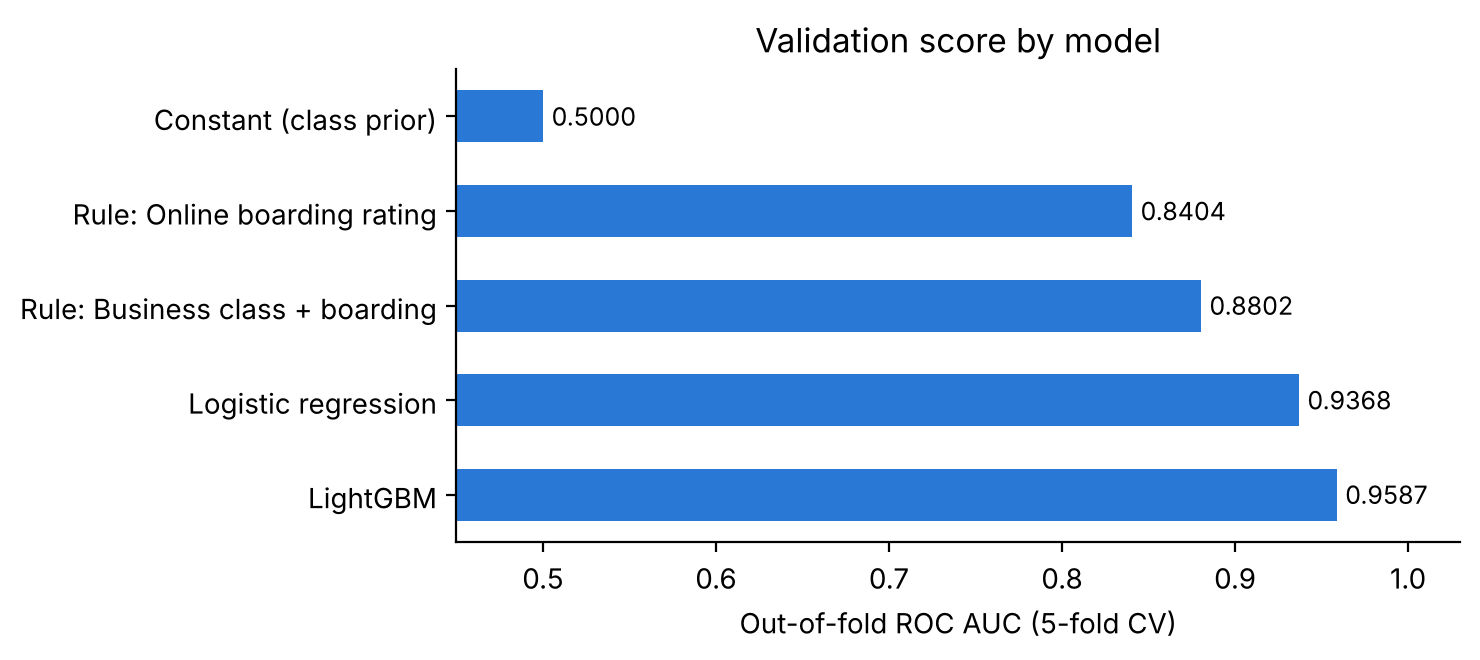

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.barh(table.index[::-1], table["OOF AUC"][::-1], color="#2a78d6", height=0.55)
for i, v in enumerate(table["OOF AUC"][::-1]):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_xlim(0.45, 1.03); ax.set_xlabel("Out-of-fold ROC AUC (5-fold CV)")
ax.set_title("Validation score by model")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("../figures/model_comparison.png", dpi=150); plt.show()

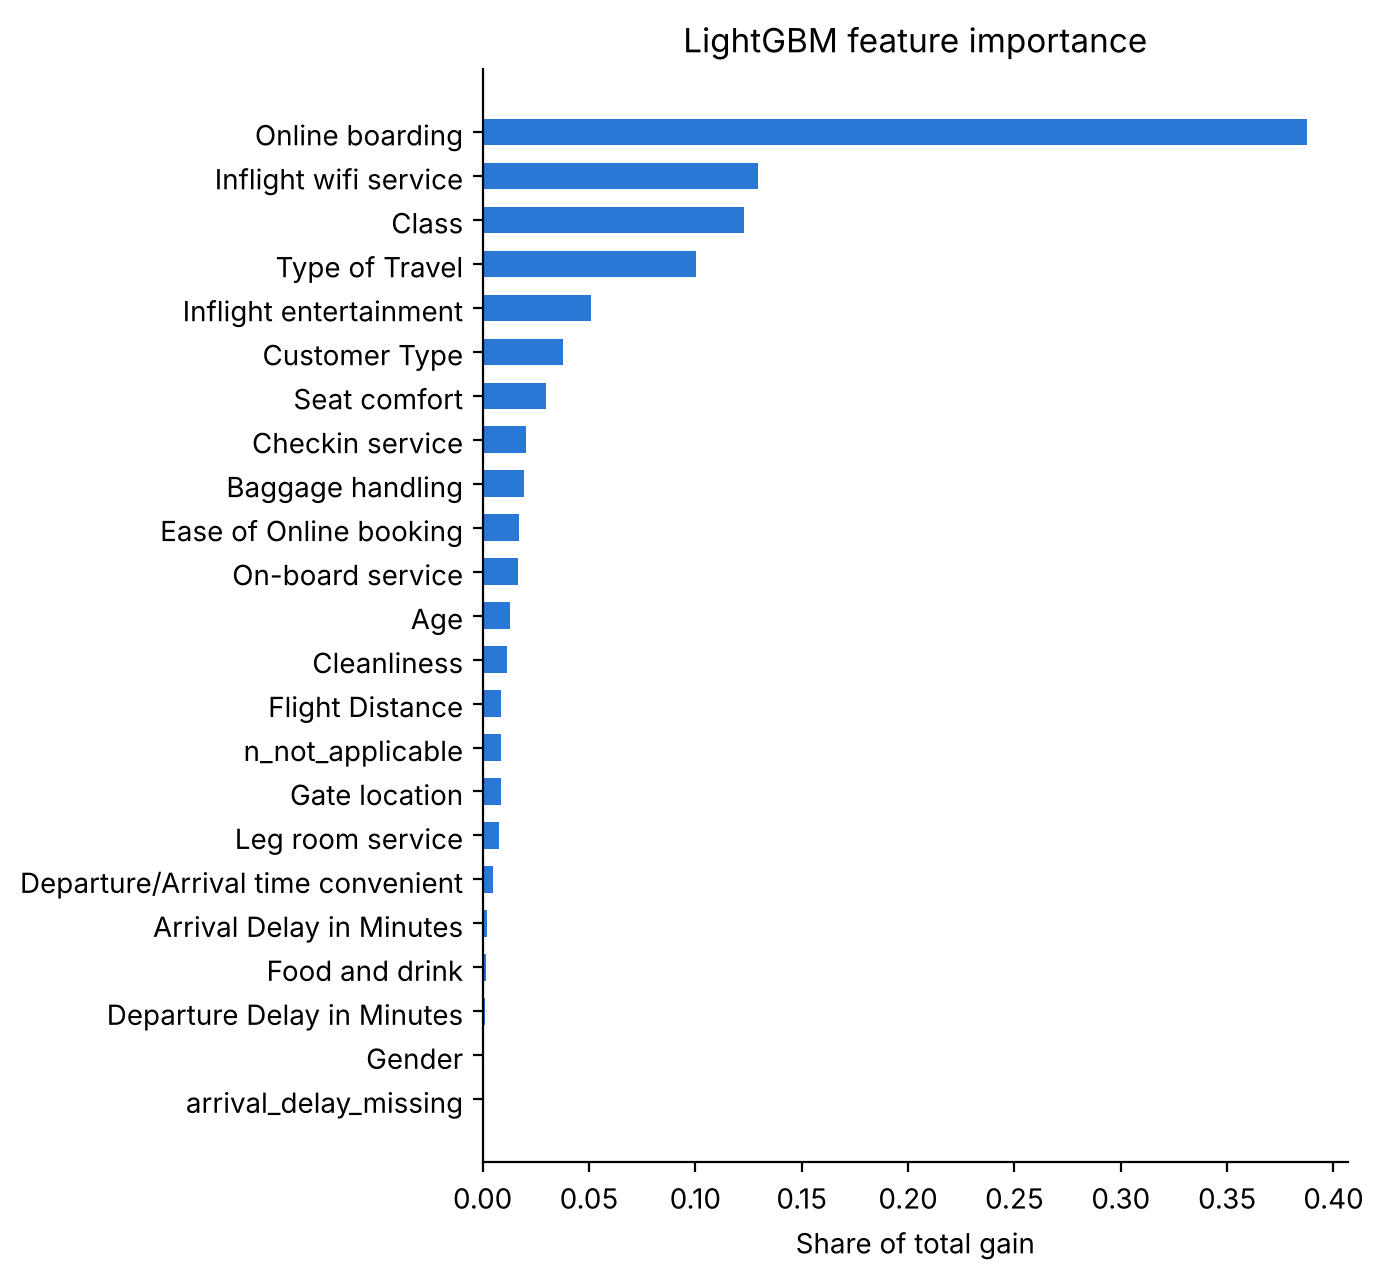

In [7]:
imp = pd.Series(importances, index=X_tree.columns).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.barh(imp.index, imp.values, color="#2a78d6", height=0.6)
ax.set_xlabel("Share of total gain"); ax.set_title("LightGBM feature importance")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("../figures/lgb_importance.png", dpi=150); plt.show()

## 5. Kaggle submission
Test prediction = average of the 5 LightGBM fold models. Format matches `sample_submission.csv`.

In [8]:
sub = pd.read_csv("../data/sample_submission.csv")
assert (sub[ID_COL].values == test[ID_COL].values).all()
sub[TARGET] = test_pred
sub.to_csv("../submissions/submission_lgb_baseline.csv", index=False)
print(sub.shape); sub.head()

(299844, 2)


,id,satisfaction
0,699635,0.230819
1,699636,0.876176
2,699637,0.911874
3,699638,0.058882
4,699639,0.043542


**Upload `submissions/submission_lgb_baseline.csv` to Kaggle** and record the public
leaderboard score in the README and the report.